**AICE Associate <font color=red>실전 모의고사 (문제)</font>** — AICE_Asso_005_실전형_다중분류_태양광발전량예측

### **태양광 발전량 예측 — <span style="color:darkgreen">출력 수준</span> 예측 모델 개발**
---

- 도메인 : 태양광 발전량 예측
- 목  표 : 발전소의 출력 수준을 3단계로 예측하는 인공지능모델 개발<br>
발전량 편차가 커 드림에너지는 정확한 발전량 예측으로 계통 연계 손실을 줄이려 합니다.<br>
그래서 드림에너지 운영팀은 보유한 발전소 데이터를 바탕으로 '출력 수준(outputLevel)'을 3가지로 분류하는 인공지능 모델을 도입하려고 합니다.<br>
드림에너지는 출력 수준 예측 결과를 업무에 활용한다면 손실을 줄이고 서비스 품질을 높일 수 있을 것으로 보고 있습니다.<br>

---

#### **<span style="color:red">[유의사항]</span>**
- <span style="color:darkgreen">각 문항의 답안은 반드시 *'# 여기에 답안코드를 작성하고 실행하세요.', '# 아래의 코드를 정정하고 실행하세요.', '# 아래 코드의 빈칸을 채우고 실행하세요.'* 등이 표시된 셀(cell)에 입력해야 합니다</span>
- <span style="color:darkgreen">제공된 시험문항 셀을 삭제하거나 답안 위치가 아닌 다른 셀에 답안코드를 작성 시 채점되지 않습니다</span>
- 답안 작성 전에 문항에 제시된 가이드를 확인하세요
- 문항에 변수명이 제시된 경우 반드시 해당 변수명을 사용하세요. 앞 문항의 결과를 뒤 문항이 이어서 사용하므로 순서대로 실행하세요
- 답안 변수(`답안3`, `답안7_1` 등)가 있는 문항은 코드 셀 맨 아래 답안 변수에 값을 입력하세요(글자는 따옴표로 감싸기, 숫자는 문항이 안내한 자릿수로 반올림)
- 막히면 문항 아래 접혀 있는 **힌트**(1~3단계)를 차례로 펼쳐 보세요
- <font color=blue>**모든 문항을 풀고 맨 마지막 셀(전체 자동 채점)을 실행하면 문항별 점수와 총점이 나옵니다.** 채점은 실행한 결과(변수·답안·실행한 코드)로 합니다</font>
- <font color=blue>**오픈북은 허용된 사이트만 참고하세요**</font>
---

#### **[학습 정보]**
- 학습 목표 : 드림에너지의 데이터로 발전소의 출력 수준을 3단계로 예측하는 AI 모델을 만들며 데이터 분석·전처리·모델링 전 과정을 수행할 수 있다
- AICE 역량 : 데이터 분석(DA1 분석 환경 구성, DA2 데이터 불러오기·구조 파악, DA3 탐색적 데이터 분석, DA4 데이터 시각화) / 데이터 전처리(DP1 이상치 처리, DP2 결측치 처리, DP3 인코딩·변수 변환, DP4 데이터 분할, DP5 스케일링) / AI 모델링(AM1 머신러닝 모델 학습·탐색, AM2 모델 해석, AM3 모델 성능 평가, AM4 딥러닝 모델 구성·학습, AM5 딥러닝 학습 결과 분석)
- 기술 스택 : pandas(import pandas as pd, read_excel, head, max, groupby, quantile, reset_index, drop, dropna, sum, isnull, astype, get_dummies, info, replace, DataFrame, sort_values, columns, shape) · seaborn(histplot, barplot) · matplotlib(import matplotlib.pyplot as plt, show, plot, title, xlabel, ylabel, legend) · scikit-learn(train_test_split, RobustScaler, fit_transform, transform, KNeighborsClassifier, fit, DecisionTreeClassifier, feature_importances_, predict, accuracy_score) · TensorFlow(Keras)(to_categorical, Input, Model, EarlyStopping, compile, fit, Dense, Dropout, history)
- 난이도 : 공식형(중급) (설계 난이도 점수 2.82 / 5)
- 예상 소요 시간 : 약 129분 (문항별 시간은 각 문항 제목 아래)
- 관련 도메인 : 태양광 발전량 예측 (에너지)

**[ 데이터 컬럼 설명 (데이터 파일명: data.xlsx) ]**

- regNo                 : 등록번호
- irradiance            : 일사량(W/㎡)
- panelTemp             : 패널 온도(℃)
- ambientTemp           : 외기 온도(℃)
- humidity              : 습도(%) (단위가 붙은 문자열)
- cloudPct              : 운량(%)
- dustIdx               : 패널 오염 지수
- tiltDeg               : 패널 경사각(도)
- site                  : 발전소
- panelType             : 패널 종류
- season                : 계절
- mount                 : 설치 방식
- outputLevel           : 출력 수준 (0: Low, 1: Mid, 2: High)

## <font color=blue>**<데이터 분석 (20점)>**</font>

> **<span style="color:red">다음 문항을 풀기 전에 </span>아래 코드를 실행하세요.**

In [1]:
import numpy as np
import seaborn as sns

### **1. 그래프 시각화에 널리 사용되는 파이썬 라이브러리 matplotlib 를 사용하려고 합니다. 별칭(alias)을 plt 로 해서 불러오세요.**

<sub>학습 목표: 분석에 필요한 파이썬 라이브러리를 관용 별칭으로 불러올 수 있다 | 역량: DA1 분석 환경 구성 | 기술: matplotlib(import matplotlib.pyplot as plt) | 난이도: 기초 | 예상 시간: 4분</sub>

- 제시된 가이드에 맞춰 코드를 작성하고 실행하세요
    - import 할 모듈 : `matplotlib.pyplot`
    - as 뒤에 쓸 이름(alias) : `plt`
- **[코드 채점]** 답안 셀에 작성한 코드(함수·인자)를 채점합니다 — 셀 맨 위 `# [N번 문항]` 주석은 지우지 말고, 셀을 꼭 실행하세요
- 배점 : 5점

---

In [2]:
# [1번 문항] 여기에 답안코드를 작성하고 실행하세요.
import matplotlib.pyplot as plt

<details><summary>힌트 1단계 (접근 방향) - 1번 문항</summary>

`import 라이브러리 as 별칭` 문법으로 라이브러리를 불러옵니다.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 1번 문항</summary>

사용할 도구: `import ... as ...`.

</details>

<details><summary>힌트 3단계 (코드 구조) - 1번 문항</summary>

코드의 **앞부분은 구조만** 보여 줍니다(`____` 자리는 가이드와 공식 문서를 보고 채우세요). **뒷부분은 주석으로 할 일만** 적었습니다 — 주석을 따라 직접 작성하세요.
```python
import ____ as ____

# ▷ 필요한 도구를 불러오기(가이드에 적힌 라이브러리)
```

</details>

### **2. AI 모델링을 위해 분석할 데이터가 엑셀 파일로 제공되었습니다. pandas로 엑셀 파일을 읽어 데이터프레임 변수명 df 에 할당하고 첫 4개 행을 출력하십시오.**

<sub>학습 목표: CSV 파일을 데이터프레임으로 읽고 행·열 구성을 확인할 수 있다 | 역량: DA2 데이터 불러오기·구조 파악 | 기술: pandas(import pandas as pd, read_excel, head) | 난이도: 쉬움 | 예상 시간: 6분</sub>

- 제시된 가이드에 맞춰 코드를 작성하고 실행하세요
    - 데이터 파일명 : data.xlsx
    - 파일은 본 문제/답안지와 동일한 경로에 있습니다
    - 읽은 결과를 담을 변수 : df
    - 파일 형식은 엑셀(.xlsx) 입니다 (엑셀 읽기에는 openpyxl 이 필요하며 Colab 에는 설치되어 있습니다)
- **[결과 변수]** 결과는 반드시 `df` 변수에 저장하세요 — 변수의 내용(모양·값)으로 채점합니다
- 확인 : 코드 셀 맨 아래 확인 줄(`print(df.shape)`)을 실행하세요.
- 참고: `shape[0]` 은 **행 수**, `shape[1]` 은 **열 수** 입니다
- 배점 : 5점

---

In [3]:
# [2번 문항] 여기에 답안코드를 작성하고 실행하세요.
import pandas as pd

df = pd.read_excel('data.xlsx')
print(df.head(4))

print(df.shape)

   regNo  irradiance  panelTemp  ambientTemp humidity  cloudPct  dustIdx  \
0    837        1687        NaN         19.4      47%      18.0     14.6   
1   1123         338       44.9         27.4      66%      69.0     30.7   
2   2021         421       35.0         24.2      66%      38.0     27.7   
3    873         970       24.8          9.9      50%      45.0     19.0   

   tiltDeg site panelType season mount  outputLevel  
0       20   C소        박막     겨울   수상형            2  
1       25   D소       다결정     여름   지붕형            0  
2       39   D소        박막     가을   지붕형            1  
3       33   D소       다결정     가을   수상형            2  
(2021, 13)


<details><summary>힌트 1단계 (접근 방향) - 2번 문항</summary>

엑셀 파일 형식에 맞는 pandas 읽기 함수를 고르세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 2번 문항</summary>

사용할 도구: `pd.read_excel`.

</details>

<details><summary>힌트 3단계 (코드 구조) - 2번 문항</summary>

코드의 **앞부분은 구조만** 보여 줍니다(`____` 자리는 가이드와 공식 문서를 보고 채우세요). **뒷부분은 주석으로 할 일만** 적었습니다 — 주석을 따라 직접 작성하세요.
```python
import ____ as ____

df = pd.____('____')
# ▷ 가이드의 다음 단계를 작성

# [df] 결과 확인
# ▷ 가이드의 다음 단계를 작성
```
- 참고 문서: <https://pandas.pydata.org/docs/reference/api/pandas.read_excel.html>

</details>

### **3. 계절(season) 별로 외기 온도(℃)(ambientTemp)의 특성을 비교하려 합니다.**

<sub>학습 목표: 집계·통계량으로 데이터의 특징을 탐색할 수 있다 | 역량: DA3 탐색적 데이터 분석 | 기술: pandas(max, groupby) | 난이도: 쉬움 | 예상 시간: 6분</sub>

- 앞 문항 결과 사용 : 2번 `df`
- 계절(season) 별 외기 온도(℃)(ambientTemp)의 **최댓값** 을 구해 변수 `grp` 에 보관하세요
    - 대상 데이터프레임 : df
- **[답안3]** 최댓값이 **가장 큰 그룹(범주)** 은 무엇인가요?
- 답안 : **[답안3]** 의 값만 코드 셀 맨 아래에 `답안3 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 5점

---

In [4]:
# [3번 문항] 여기에 답안코드를 작성하고 실행하세요.
grp = df.groupby('season')['ambientTemp'].max()
print(grp)
답안3 = '가을'

season
가을    57.4
겨울    51.6
봄     47.4
여름    44.2
Name: ambientTemp, dtype: float64


<details><summary>힌트 1단계 (접근 방향) - 3번 문항</summary>

범주별로 묶어서 하나의 통계량을 구하는 패턴입니다. grp 에서 값이 가장 큰 행의 인덱스를 찾으세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 3번 문항</summary>

사용할 도구: `groupby`, `max`, `idxmax`, `sort_values`.

</details>

<details><summary>힌트 3단계 (코드 구조) - 3번 문항</summary>

코드의 **앞부분은 구조만** 보여 줍니다(`____` 자리는 가이드와 공식 문서를 보고 채우세요). **뒷부분은 주석으로 할 일만** 적었습니다 — 주석을 따라 직접 작성하세요.
```python
grp = df.____('____')['____'].____()
# ▷ 가이드의 다음 단계를 작성

# [답안3] 실행한 결과를 입력하세요
# ▷ 실행해서 결과 확인 — `idxmax` 사용
```
- 참고 문서: <https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.max.html>
- 참고 문서: <https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.groupby.html>
- 참고 문서: <https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.idxmax.html>

</details>

### **4. 패널 경사각(도)(tiltDeg)의 분포를 패널 종류 별로 나누어 확인하려 합니다.**

<sub>학습 목표: 그래프로 변수의 분포와 관계를 시각화할 수 있다 | 역량: DA4 데이터 시각화 | 기술: seaborn(histplot) · matplotlib(show) | 난이도: 보통 | 예상 시간: 8분</sub>

- 앞 문항 결과 사용 : 1번 `plt` · 2번 `df`
- 대상 데이터프레임 : df
- seaborn 의 histplot 으로 tiltDeg 의 분포를 그리세요
- panelType 로 색상을 구분(hue)하세요
- 구간 수(bins)는 20, 막대 표시 방식(multiple)은 'stack' 로 설정하세요
- **[코드 채점]** 답안 셀에 작성한 코드(함수·인자)를 채점합니다 — 셀 맨 위 `# [N번 문항]` 주석은 지우지 말고, 셀을 꼭 실행하세요
- 배점 : 5점

---

/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 48149 (\N{HANGUL SYLLABLE BAG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 47561 (\N{HANGUL SYLLABLE MAG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 45796 (\N{HANGUL SYLLABLE DA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 44208 (\N{HANGUL SYLLABLE GYEOL}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 51221 (\N{HANGUL SYLLABLE JEONG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/u

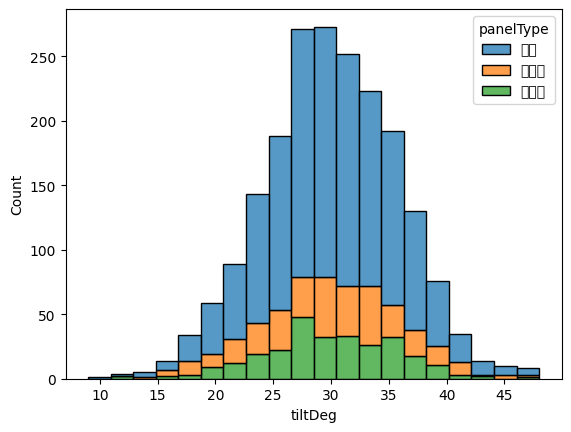

In [5]:
# [4번 문항] 여기에 답안코드를 작성하고 실행하세요.
sns.histplot(data=df, x='tiltDeg', hue='panelType', bins=20, multiple='stack')
plt.show()

<details><summary>힌트 1단계 (접근 방향) - 4번 문항</summary>

수치형 변수의 분포를 그룹별로 나누어 히스토그램으로 그립니다.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 4번 문항</summary>

사용할 도구: `sns.histplot`.

</details>

<details><summary>힌트 3단계 (코드 구조) - 4번 문항</summary>

코드의 **앞부분은 구조만** 보여 줍니다(`____` 자리는 가이드와 공식 문서를 보고 채우세요). **뒷부분은 주석으로 할 일만** 적었습니다 — 주석을 따라 직접 작성하세요.
```python
import ____ as ____
import ____ as ____

sns.____(data=df, x='____', hue='____', bins=____, multiple='____')
# ▷ 가이드의 다음 단계를 작성

# ▷ 실행해서 결과 확인 — `histplot` 사용
# ▷ 가이드의 다음 단계를 작성
```
- 참고 문서: <https://seaborn.pydata.org/generated/seaborn.histplot.html>

</details>

## <font color=blue>**<데이터 전처리 (30점)>**</font>

### **5. 패널 오염 지수(dustIdx) 컬럼의 이상치를 IQR 기준으로 제거할 계획입니다. 아래 안내대로 처리하십시오.**

<sub>학습 목표: 사분위 범위(IQR) 등의 기준으로 이상치를 찾아 처리할 수 있다 | 역량: DP1 이상치 처리 | 기술: pandas(quantile, reset_index, drop) | 난이도: 보통 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 2번 `df`
- 아래 안내대로 코드를 작성하고 실행하세요
    - 대상 데이터프레임 : df
    - 사분위수(Q1, Q3)와 IQR 을 계산하세요
    - lower_fence = Q1 - 3.0 x IQR, upper_fence = Q3 + 3.0 x IQR 로 정의하세요
    - dustIdx 이(가) 두 fence 밖에 있는 행을 삭제하세요
    - ② 식별번호 열 삭제 — 식별자 컬럼 regNo 도 삭제하고 인덱스를 0부터 다시 매겨 df_temp 에 보관하세요
- **[결과 변수]** 결과는 반드시 `df_temp` 변수에 저장하세요 — 변수의 내용(모양·값)으로 채점합니다
- 확인 : 코드 셀 맨 아래 확인 줄(`print(df_temp.shape)`)을 실행하세요.
- 배점 : 6점

---

In [6]:
# [5번 문항] 여기에 답안코드를 작성하고 실행하세요.
Q1 = df['dustIdx'].quantile(0.25)
Q3 = df['dustIdx'].quantile(0.75)
IQR = Q3 - Q1
lower_fence = Q1 - 3.0 * IQR
upper_fence = Q3 + 3.0 * IQR

outlier_idx = df[(df['dustIdx'] < lower_fence) | (df['dustIdx'] > upper_fence)].index
df_temp = df.drop(index=outlier_idx).drop(columns=['regNo']).reset_index(drop=True)

print(df_temp.shape)

(1953, 12)


<details><summary>힌트 1단계 (접근 방향) - 5번 문항</summary>

분위수로 fence 를 계산하고, 범위 밖 여부를 불리언으로 만든 뒤 반대로 선택합니다. **개념** `quantile(0.25)` 는 1사분위수(Q1), `quantile(0.75)` 는 3사분위수(Q3), IQR = Q3 − Q1 입니다. 행을 지운 뒤 `reset_index(drop=True)` 로 번호를 0부터 다시 매기고, 옛 인덱스는 컬럼으로 남기지 않습니다.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 5번 문항</summary>

사용할 도구: `quantile`, `drop`, `reset_index`.

</details>

<details><summary>힌트 3단계 (코드 구조) - 5번 문항</summary>

코드의 **앞부분은 구조만** 보여 줍니다(`____` 자리는 가이드와 공식 문서를 보고 채우세요). **뒷부분은 주석으로 할 일만** 적었습니다 — 주석을 따라 직접 작성하세요.
```python
q1 = df['____'].____(____)
q3 = df['____'].____(____)
iqr = q3 - q1

lower_fence = q1 - ____ * iqr
# ▷ `upper_fence` 에 결과를 저장

# ▷ `is_out` 에 결과를 저장
# ▷ `df_temp` 에 결과를 저장 — `reset_index`, `drop` 사용

# [df_temp] 결과 확인
# ▷ 가이드의 다음 단계를 작성
```
- 참고 문서: <https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.quantile.html>
- 참고 문서: <https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.reset_index.html>
- 참고 문서: <https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.drop.html>

</details>

### **6. 데이터에 결측치가 있을 경우 AI모델링의 성능이 저하될 수 있습니다. AI모델링할 때 부정적 영향이 없도록 아래 안내대로 결측치를 처리하세요.**

<sub>학습 목표: 결측치를 확인하고 삭제하거나 대체할 수 있다 | 역량: DP2 결측치 처리 | 기술: pandas(dropna, sum, isnull) | 난이도: 쉬움 | 예상 시간: 8분</sub>

- 앞 문항 결과 사용 : 5번 `df_temp`
- 아래 가이드에 따라 코드를 작성하고 실행하세요
    - 대상 데이터프레임 : df_temp
    - 결측치 개수를 확인한 후에 결측치가 있는 행을 모두 삭제하세요
    - 전처리가 반영된 데이터프레임은 변수명 df_na 에 저장하세요
    - 결측치가 사라졌는지 확인하세요
- **[결과 변수]** 결과는 반드시 `df_na` 변수에 저장하세요 — 변수의 내용(모양·값)으로 채점합니다
- 확인 : 코드 셀 맨 아래 확인 줄(`print(df_na.shape)`)을 실행하세요.
- 배점 : 6점

---

In [7]:
# [6번 문항] 여기에 답안코드를 작성하고 실행하세요.
print(df_temp.isnull().sum())
df_na = df_temp.dropna().copy()
print(df_na.isnull().sum())

print(df_na.shape)

irradiance       0
panelTemp      183
ambientTemp      0
humidity         0
cloudPct        95
dustIdx          0
tiltDeg          0
site             0
panelType        0
season           0
mount            0
outputLevel      0
dtype: int64
irradiance     0
panelTemp      0
ambientTemp    0
humidity       0
cloudPct       0
dustIdx        0
tiltDeg        0
site           0
panelType      0
season         0
mount          0
outputLevel    0
dtype: int64
(1692, 12)


<details><summary>힌트 1단계 (접근 방향) - 6번 문항</summary>

빈칸을 채워 코드를 완성한 뒤 실행하세요. **개념** 결측치는 `isnull().sum()` 으로 세고, `dropna()` 로 행을 지우거나 `fillna()` 로 채웁니다.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 6번 문항</summary>

사용할 도구: `isnull`, `sum`, `dropna`.

</details>

<details><summary>힌트 3단계 (코드 구조) - 6번 문항</summary>

코드의 **앞부분은 구조만** 보여 줍니다(`____` 자리는 가이드와 공식 문서를 보고 채우세요). **뒷부분은 주석으로 할 일만** 적었습니다 — 주석을 따라 직접 작성하세요.
```python
print( '____', df_temp.____().____() )
df_na = df_temp.____()
# ▷ 실행해서 결과 확인 — `sum`, `isnull` 사용

# [df_na] 결과 확인
# ▷ 가이드의 다음 단계를 작성
```
- 참고 문서: <https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.sum.html>
- 참고 문서: <https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.isnull.html>
- 참고 문서: <https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.dropna.html>

</details>

### **7. 습도(%)(humidity) 컬럼이 숫자가 아닌 문자열로 저장되어 있습니다. 숫자형으로 바꾼 뒤 인코딩하십시오.**

<sub>학습 목표: 범주형 변수를 인코딩하고 변수를 정리·변환할 수 있다 | 역량: DP3 인코딩·변수 변환 | 기술: pandas(astype, get_dummies, info, replace) | 난이도: 보통 | 예상 시간: 8분</sub>

- 앞 문항 결과 사용 : 2번 `pd` · 6번 `df_na`
- 대상 데이터프레임 : df_na
- humidity 의 천 단위 쉼표(,)와 단위('%')를 제거하고 float 으로 변환해 df_na[ 'humidity' ] 에 다시 저장하세요 (str.replace 활용)
- 남은 문자열 컬럼 site, panelType, season, mount 을(를) get_dummies(drop_first=True)로 인코딩해 df_enc 에 담으세요
- 아래 코드 셀의 빈칸 `< blank07_1 >`, `< blank07_2 >` 를 채우고 실행하세요
- 빈칸에 들어갈 내용(함수·인자·모듈 이름)을 코드 셀 맨 아래 `답안7_1`, `답안7_2` 변수에 각각 저장하세요
    - 예시) 답안7_0 = 'data'
- 배점 : 6점

---

In [8]:
# [7번 문항] 아래 코드의 빈칸을 채우고 실행하세요.
df_na['humidity'] = df_na['humidity'].str.replace(',', '', regex=False).str.replace('%', '', regex=False).astype(float)

df_enc = pd.get_dummies(data=df_na, columns=['site', 'panelType', 'season', 'mount'], drop_first=True)
df_enc.info()

답안7_1 = 'replace'
답안7_2 = 'astype'

<class 'pandas.core.frame.DataFrame'>
Index: 1692 entries, 1 to 1952
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   irradiance     1692 non-null   int64  
 1   panelTemp      1692 non-null   float64
 2   ambientTemp    1692 non-null   float64
 3   humidity       1692 non-null   float64
 4   cloudPct       1692 non-null   float64
 5   dustIdx        1692 non-null   float64
 6   tiltDeg        1692 non-null   int64  
 7   outputLevel    1692 non-null   int64  
 8   site_B소        1692 non-null   bool   
 9   site_C소        1692 non-null   bool   
 10  site_D소        1692 non-null   bool   
 11  panelType_단결정  1692 non-null   bool   
 12  panelType_박막   1692 non-null   bool   
 13  season_겨울      1692 non-null   bool   
 14  season_봄       1692 non-null   bool   
 15  season_여름      1692 non-null   bool   
 16  mount_지붕형      1692 non-null   bool   
 17  mount_지상형      1692 non-null   bool   
dtypes: bool(10), 

<details><summary>힌트 1단계 (접근 방향) - 7번 문항</summary>

문자열 컬럼의 일부 문자를 제거한 뒤 실수형으로 바꿉니다. 코드의 흐름(앞뒤 변수와 인자)을 보고 이 자리에 들어갈 함수·옵션 이름을 떠올려 보세요. **개념** 원-핫 인코딩은 범주를 0/1 컬럼으로 바꿉니다(`drop_first=True` 면 범주마다 첫 컬럼 하나를 뺍니다).

</details>

<details><summary>힌트 2단계 (사용할 도구) - 7번 문항</summary>

빈칸에 들어갈 것은 pandas(데이터프레임·시리즈 메서드) 쪽 이름입니다. 공식 문서 목록에서 찾아보세요: [pandas](https://pandas.pydata.org/docs/reference/index.html)

</details>

<details><summary>힌트 3단계 (코드 구조) - 7번 문항</summary>

코드 구조입니다. `____` 자리에 들어갈 이름은 아래 공식 문서에서 확인하세요(오픈북 사이트).
```python
df_na['humidity'] = df_na['humidity'].str.____(',', '', regex=False).str.replace('%', '', regex=False).____(float)

df_enc = pd.get_dummies(data=df_na, columns=['site', 'panelType', 'season', 'mount'], drop_first=True)
df_enc.info()

답안7_1 = '____'   # 빈칸 1에 넣은 이름
답안7_2 = '____'   # 빈칸 2에 넣은 이름
```
- 참고 문서: <https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.replace.html>
- 참고 문서: <https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.astype.html>

</details>

### **8. 모델 성능을 확인할 검증 데이터를 따로 떼어 두려고 합니다. 다음 지침에 따라 분리하세요.**

<sub>학습 목표: 피처와 레이블을 나누고 훈련·검증 데이터로 분할할 수 있다 | 역량: DP4 데이터 분할 | 기술: pandas(drop) · scikit-learn(train_test_split) | 난이도: 쉬움 | 예상 시간: 8분</sub>

- 앞 문항 결과 사용 : 7번 `df_enc`
- 대상 데이터프레임 : df_enc
- 출력 수준(outputLevel) 컬럼을 레이블값 y 로, 나머지 컬럼을 피처값 X 로 할당하세요
- 변수명 : X_train, X_valid, y_train, y_valid (훈련 피처/검증 피처/훈련 레이블/검증 레이블)
- 결과를 재현할 수 있게 random_state 값을 42 로 지정하세요
- 훈련과 검증 데이터셋 분리 — 훈련 : 검증 = 80:20 (train_size=0.8)
- 훈련과 검증 데이터셋의 클래스 비율을 동일하게 하는 옵션(stratify)을 설정하세요
- 분리에는 sklearn.model_selection 의 train_test_split 을 사용하세요
- **[결과 변수]** 결과는 반드시 `X_valid` 변수에 저장하세요 — 변수의 내용(모양·값)으로 채점합니다
- 확인 : 코드 셀 맨 아래 확인 줄(`print(len(X_valid))`)을 실행하세요.
- 배점 : 6점

---

In [9]:
# [8번 문항] 여기에 답안코드를 작성하고 실행하세요.
from sklearn.model_selection import train_test_split

y = df_enc['outputLevel']
X = df_enc.drop(columns=['outputLevel'])
X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, train_size=0.8, random_state=42, stratify=y
)

print(len(X_valid))

339


<details><summary>힌트 1단계 (접근 방향) - 8번 문항</summary>

피처와 레이블을 나눈 뒤, 훈련/검증으로 무작위 분할합니다.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 8번 문항</summary>

사용할 도구: `train_test_split`, `drop`.

</details>

<details><summary>힌트 3단계 (코드 구조) - 8번 문항</summary>

코드의 **앞부분은 구조만** 보여 줍니다(`____` 자리는 가이드와 공식 문서를 보고 채우세요). **뒷부분은 주석으로 할 일만** 적었습니다 — 주석을 따라 직접 작성하세요.
```python
from sklearn.model_selection import ____

X = df_enc.____('____', axis=____)
# ▷ `y` 에 결과를 저장

# ▷ `(X_train, X_valid, y_train, y_valid)` 에 결과를 저장 — `train_test_split` 사용

# [X_valid] 결과 확인
# ▷ 가이드의 다음 단계를 작성
```
- 참고 문서: <https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.drop.html>
- 참고 문서: <https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html>

</details>

### **9. 스케일링을 통해 변수들의 단위(범위) 차이가 모델에 미치는 영향을 줄이려 합니다. (중앙값/IQR 기반(이상치에 강건))**

<sub>학습 목표: 훈련 데이터로 스케일러를 학습해 검증 데이터에 같은 기준을 적용할 수 있다 | 역량: DP5 스케일링 | 기술: scikit-learn(RobustScaler, fit_transform, transform) | 난이도: 보통 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 8번 `X_train`, `X_valid`
- 다음 지침에 따라 스케일링 처리하는데 에러가 나고 있습니다. 코드의 오류를 정정하세요
    - sklearn.preprocessing 에서 알맞은 scikit-learn 도구를 import 하세요
    - 알맞은 scikit-learn 도구를 sc 변수에 지정하세요
    - 훈련 데이터(X_train)에 대해 스케일러를 학습시키고 변환을 적용해 X_train 에 다시 담으세요
    - 검증 데이터(X_valid)에는 **학습된 기준을 그대로** 적용(변환만)해 X_valid 에 보관하세요
- **[답안9]** 알맞은 scikit-learn 도구 적용 후 검증 데이터(X_valid)의 **최솟값**을 **소수 둘째 자리까지** 기입하세요
- 답안 : **[답안9]** 의 값만 코드 셀 맨 아래에 `답안9 = 값` 형태로 입력하세요
- 오류는 2곳입니다 — 실행 오류뿐 아니라 실행은 되지만 가이드와 다르게 동작하는 부분도 바로잡으세요
- 배점 : 6점

---

In [12]:
# [9번 문항] 아래의 코드를 정정하고 실행하세요.
from sklearn.preprocessing import RobustScaler

sc = RobustScaler()
X_train = sc.fit_transform(X_train)
X_valid = sc.transform(X_valid)
round(float(np.min(X_valid)), 2)

답안9 = -2.15

<details><summary>힌트 1단계 (접근 방향) - 9번 문항</summary>

고칠 곳은 2군데입니다. 실행 오류뿐 아니라 실행은 되지만 가이드와 다르게 동작하는 줄도 찾으세요. 훈련 데이터로 fit, 검증 데이터는 이미 학습한 기준으로 변환만 하는 메서드 만 하는 규칙을 떠올리세요. 변환된 검증 데이터 전체에서 최솟값을 구하세요. **개념** 훈련 데이터는 `fit_transform`(기준 학습 + 변환), 검증 데이터는 `transform`(변환만) — 검증 데이터로 기준을 다시 배우면 안 됩니다.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 9번 문항</summary>

사용할 도구: `np.min`, `round`.

</details>

<details><summary>힌트 3단계 (코드 구조) - 9번 문항</summary>

코드의 **앞부분은 구조만** 보여 줍니다(`____` 자리는 가이드와 공식 문서를 보고 채우세요). **뒷부분은 주석으로 할 일만** 적었습니다 — 주석을 따라 직접 작성하세요.
```python
import ____ as ____

from sklearn.preprocessing import ____

sc = ____()
# ▷ `X_train` 에 결과를 저장 — `fit_transform` 사용
# ▷ `X_valid` 에 결과를 저장 — `transform` 사용

# [답안9] 실행한 결과를 입력하세요
# ▷ 실행해서 결과 확인 — `min` 사용
```
- 참고 문서: <https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.RobustScaler.html>
- 참고 문서: <https://scikit-learn.org/stable/api/index.html>
- 참고 문서: <https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.min.html>

</details>

## <font color=blue>**<AI 모델링 (50점)>**</font>

### **10. 출력 수준(outputLevel)을(를) 예측하는 머신러닝 모델을 만들려고 합니다. KNN와(과) DecisionTree는 각각 서로 다른 방식으로 예측하는 모델입니다.**

<sub>학습 목표: 머신러닝 모델에 하이퍼파라미터를 지정해 학습하고 결과를 확인할 수 있다 | 역량: AM1 머신러닝 모델 학습·탐색 | 기술: scikit-learn(KNeighborsClassifier, fit, DecisionTreeClassifier) | 난이도: 쉬움 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 8번 `y_train` · 9번 `X_train`
- KNN 모델을 아래와 같이 만들어 `knn` 변수에 저장하고 학습시키세요
    - 하이퍼파라미터 : n_neighbors=7, weights='uniform'
    - 앞서 분리한 훈련데이터셋(X_train, y_train)으로 fit 함수를 사용해 학습시키세요
- DecisionTree 모델을 아래와 같이 만들어 `dt` 변수에 저장하고 학습시키세요
    - 하이퍼파라미터 : max_depth=8, min_samples_leaf=10
    - 난수 시드(random_state) : 2024
    - 앞서 분리한 훈련데이터셋(X_train, y_train)으로 fit 함수를 사용해 학습시키세요
- **[답안10]** 학습된 `dt`(DecisionTree) 의 **잎(leaf) 노드 수** `dt.get_n_leaves()` 는 몇 개입니까?
- 답안 : **[답안10]** 의 값만 코드 셀 맨 아래에 `답안10 = 값` 형태로 입력하세요
- 배점 : 10점

---

In [16]:
# [10번 문항] 여기에 답안코드를 작성하고 실행하세요.

from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=7, weights='uniform')
knn.fit(X_train, y_train)

from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(max_depth=8, min_samples_leaf=10, random_state=2024)
dt.fit(X_train, y_train)

dt.get_n_leaves()

np.int64(64)

In [17]:
# [10번 문항] 여기에 답안코드를 작성하고 실행하세요.
답안10 = 64

<details><summary>힌트 1단계 (접근 방향) - 10번 문항</summary>

모델 객체를 하이퍼파라미터와 함께 만들고 훈련 데이터로 fit 합니다. 결정나무 모델의 get_n_leaves() 메서드를 호출하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 10번 문항</summary>

사용할 도구: `KNeighborsClassifier`, `fit`, `DecisionTreeClassifier`, `get_n_leaves`.

</details>

<details><summary>힌트 3단계 (코드 구조) - 10번 문항</summary>

코드의 **앞부분은 구조만** 보여 줍니다(`____` 자리는 가이드와 공식 문서를 보고 채우세요). **뒷부분은 주석으로 할 일만** 적었습니다 — 주석을 따라 직접 작성하세요.
```python
from sklearn.neighbors import ____

knn = ____(n_neighbors=____, weights='____')
knn.fit(X_train, y_train)

# ▷ 필요한 도구를 불러오기(가이드에 적힌 라이브러리)

# ▷ `dt` 에 결과를 저장 — `DecisionTreeClassifier` 사용
# ▷ 실행해서 결과 확인 — `fit` 사용

# [답안10] 실행한 결과를 입력하세요
# ▷ 실행해서 결과 확인 — `get_n_leaves` 사용
```
- 참고 문서: <https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsClassifier.html>
- 참고 문서: <https://scikit-learn.org/stable/api/index.html>
- 참고 문서: <https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html>

</details>

### **11. 모델의 해석력과 개선 방향을 이해하기 위해 DecisionTree 모델의 변수중요도를 파악하려고 합니다.**

<sub>학습 목표: 변수 중요도·계수로 모델이 어떤 변수에 의존하는지 해석할 수 있다 | 역량: AM2 모델 해석 | 기술: pandas(DataFrame, sort_values, columns) · seaborn(barplot) · matplotlib(show) · scikit-learn(feature_importances_) | 난이도: 보통 | 예상 시간: 12분</sub>

- 앞 문항 결과 사용 : 1번 `plt` · 2번 `pd` · 8번 `X` · 10번 `dt`
- 아래 안내대로 모델의 변수중요도를 파악하는데 에러가 나고 있습니다. 코드의 오류를 정정하세요
    - 앞서 학습시킨 DecisionTree 모델 `dt` 를 사용하세요
    - 변수중요도 점수와 변수 이름(X.columns)을 매핑하여 DataFrame(fi)을 만드세요
    - 변수중요도 점수를 기준으로 내림차순 정렬하고 Top 10 개만 선정하세요
    - 변수중요도 점수를 막대 그래프(seaborn barplot)로 시각화하세요
- **[답안11]** 출력된 그래프에서 **가장 높은 중요도**를 보이는 변수명을 쓰세요
- 답안 : **[답안11]** 의 값만 코드 셀 맨 아래에 `답안11 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 오류는 3곳입니다 — 실행 오류뿐 아니라 실행은 되지만 가이드와 다르게 동작하는 부분도 바로잡으세요
- 배점 : 10점

---

/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 48388 (\N{HANGUL SYLLABLE BOM}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 44200 (\N{HANGUL SYLLABLE GYEO}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 50872 (\N{HANGUL SYLLABLE UL}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 49548 (\N{HANGUL SYLLABLE SO}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


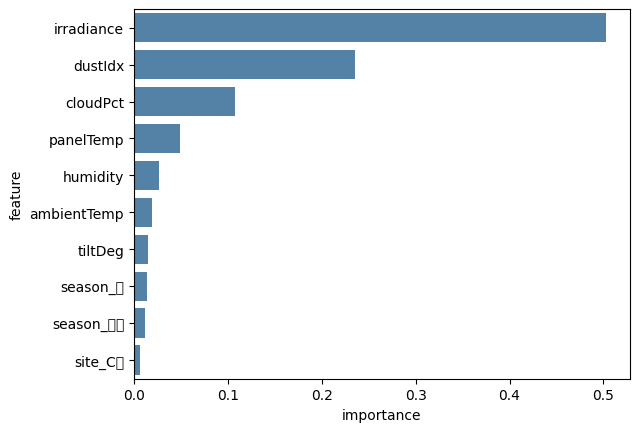

In [20]:
# [11번 문항] 아래의 코드를 정정하고 실행하세요.

fi = pd.DataFrame({'feature': X.columns, 'importance': dt.feature_importances_})
fi = fi.sort_values(by='importance', ascending=False)[:10]
sns.barplot(x='importance', y='feature', data=fi, color='steelblue')
plt.show()

답안11 = 'irradiance'

<details><summary>힌트 1단계 (접근 방향) - 11번 문항</summary>

고칠 곳은 3군데입니다. 실행 오류뿐 아니라 실행은 되지만 가이드와 다르게 동작하는 줄도 찾으세요. 변수 중요도를 DataFrame 으로 만들고 정렬해 그리는 흐름을 점검하세요. fi 의 첫 번째 행(가장 큰 중요도)의 feature 값을 보세요. **개념** 이름 끝의 `_` 는 학습(fit) 뒤에 생기는 속성이라는 표시이고, `.` 은 객체의 속성·메서드에 접근하는 기호입니다.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 11번 문항</summary>

사용할 도구: 값 기준으로 정렬하는 메서드, `iloc`.

</details>

<details><summary>힌트 3단계 (코드 구조) - 11번 문항</summary>

코드의 **앞부분은 구조만** 보여 줍니다(`____` 자리는 가이드와 공식 문서를 보고 채우세요). **뒷부분은 주석으로 할 일만** 적었습니다 — 주석을 따라 직접 작성하세요.
```python
import ____ as ____
import ____ as ____
import ____ as ____

fi = pd.____({'____': X.columns, '____': dt.____})
# ▷ `fi` 에 결과를 저장 — `sort_values` 사용
# ▷ 실행해서 결과 확인 — `barplot` 사용
# ▷ 가이드의 다음 단계를 작성

# [답안11] 실행한 결과를 입력하세요
# ▷ 가이드의 다음 단계를 작성
```
- 참고 문서: <https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.sort_values.html>
- 참고 문서: <https://seaborn.pydata.org/generated/seaborn.barplot.html>

</details>

### **12. 앞서 학습시킨 KNN와(과) DecisionTree 모델의 성능을 평가하려고 합니다.**

<sub>학습 목표: 평가 지표로 두 모델의 성능을 비교할 수 있다 | 역량: AM3 모델 성능 평가 | 기술: scikit-learn(predict, accuracy_score) | 난이도: 쉬움 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 8번 `y_valid` · 9번 `X_valid` · 10번 `dt`, `knn`
- 다음 지침에 따라 각 모델의 Accuracy(정확도) 를 산출하려는데 에러가 나고 있습니다. 코드의 오류를 정정하세요
    - 앞서 학습시킨 knn 와 dt 모델을 사용하세요
    - 성능 평가는 **검증데이터셋(X_valid, y_valid)** 을 활용하세요
    - 두 모델의 Accuracy(정확도) 값을 각각 knn_score, dt_score 변수에 저장하고 출력하세요
- **[답안12]** 두 모델의 Accuracy(정확도) 결과를 비교했을 때, 성능이 **더 우수한** 모델은 무엇인가요? (KNN / DecisionTree 중 하나)
- 답안 : **[답안12]** 의 값만 코드 셀 맨 아래에 `답안12 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 오류는 3곳입니다 — 실행 오류뿐 아니라 실행은 되지만 가이드와 다르게 동작하는 부분도 바로잡으세요
- 평가 지표의 방향: 정확도(accuracy)·F1·결정계수(R²)·`score` 는 **높을수록 좋음**, MAE·MSE·RMSE 는 **낮을수록 좋음**
- 배점 : 10점

---

In [21]:
# [12번 문항] 아래의 코드를 정정하고 실행하세요.
from sklearn.metrics import accuracy_score

y_pred_knn = knn.predict(X_valid)
y_pred_dt = dt.predict(X_valid)

knn_score = accuracy_score(y_valid, y_pred_knn)
dt_score = accuracy_score(y_valid, y_pred_dt)
print(knn_score, dt_score)

답안12 = 'DecisionTree'

0.6194690265486725 0.6755162241887905


<details><summary>힌트 1단계 (접근 방향) - 12번 문항</summary>

고칠 곳은 3군데입니다. 실행 오류뿐 아니라 실행은 되지만 가이드와 다르게 동작하는 줄도 찾으세요. Accuracy(정확도) 를 계산하는 흐름(예측 -> 지표 함수)을 점검하세요. 값이 클수록 우수한 지표입니다. 두 점수를 비교하세요. **개념** 손실·오차(MAE·MSE·RMSE)는 작을수록, 정확도·F1·R² 는 클수록 좋은 모델입니다.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 12번 문항</summary>

가이드에 언급된 함수를 확인하세요.

</details>

<details><summary>힌트 3단계 (코드 구조) - 12번 문항</summary>

코드의 **앞부분은 구조만** 보여 줍니다(`____` 자리는 가이드와 공식 문서를 보고 채우세요). **뒷부분은 주석으로 할 일만** 적었습니다 — 주석을 따라 직접 작성하세요.
```python
from sklearn.metrics import ____

y_pred_knn = knn.predict(X_valid)
y_pred_dt = dt.predict(X_valid)

# ▷ `knn_score` 에 결과를 저장 — `accuracy_score` 사용
# ▷ `dt_score` 에 결과를 저장 — `accuracy_score` 사용
# ▷ 가이드의 다음 단계를 작성

# [답안12] 실행한 결과를 입력하세요
# ▷ 가이드의 다음 단계를 작성
```
- 참고 문서: <https://scikit-learn.org/stable/api/index.html>
- 참고 문서: <https://scikit-learn.org/stable/modules/generated/sklearn.metrics.accuracy_score.html>

</details>

> **<span style="color:red">다음 문항을 풀기 전에 </span>아래 코드를 실행하세요. (tensorflow 필요)**

In [23]:
import tensorflow as tf
from tensorflow.keras.models import Sequential, Model, load_model
from tensorflow.keras.layers import Input, Dense, Activation, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam, RMSprop, Nadam, SGD
from tensorflow.keras.regularizers import l2
from tensorflow.keras.utils import to_categorical

tf.random.set_seed(1)

### **13. 출력 수준(outputLevel)을(를) 예측하는 딥러닝 모델을 만들려고 합니다. 가이드에 맞춰 신경망을 구성한 뒤 학습까지 진행하세요.**

<sub>학습 목표: 주어진 구조대로 Keras 딥러닝 모델을 구성하고 학습할 수 있다 | 역량: AM4 딥러닝 모델 구성·학습 | 기술: pandas(shape) · TensorFlow(Keras)(to_categorical, Input, Model, EarlyStopping) | 난이도: 최상 | 예상 시간: 19분</sub>

- 앞 문항 결과 사용 : 8번 `y_train`, `y_valid` · 9번 `X_train`, `X_valid`
- 아래 **모델 구조도(topology)** 와 가이드를 함께 참고하세요
- 아래 조건대로 모델을 구현하고 학습하세요
    - 딥러닝 프레임워크는 tensorflow 를 씁니다
    - Sequential 이 아니라 **함수형 API**로 구성하세요: `Input(shape=(X_train.shape[1],))` 로 입력을 만들고, 각 층을 `층(앞 텐서)` 형태로 이어 붙인 뒤 `Model(inputs=..., outputs=...)` 로 `model` 을 만드세요
    - Dense 은닉층 1개를 노드 수 [64] 순서로 쌓고, 활성화 함수는 'relu' 를 쓰세요
    - 조기 종료 : EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True) 를 만들어 estop 에 보관하세요
    - 비율 0.2 의 Dropout 층을 첫 번째 은닉층 뒤에 넣으세요
    - 마지막 Dense 층 : 노드 3개 · 활성화 함수 'softmax'
    - 모델을 컴파일할 때 optimizer 는 adam, 손실 함수는 categorical_crossentropy, 평가지표는 [accuracy] 로 하세요
    - batch_size 는 64, epochs 는 20 로 학습하고 학습정보는 history 변수에 보관하세요 (검증 데이터: X_valid, 검증 레이블)
    - 안내된 내용 외 별도의 파라미터를 입력하지 마세요
- **[결과 변수]** 모델은 `model`, 학습 기록은 `history` 변수에 저장하세요 — 모델 구조(층 수·파라미터 수)와 학습 설정으로 채점합니다
- 확인 : 코드 셀 맨 아래 `print(model.count_params())`을 실행해 확인하세요
- 배점 : 10점

---

**[모델 구조도]**

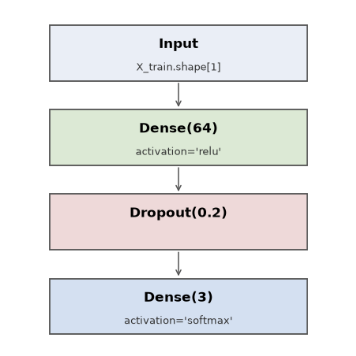

In [24]:
# [13번 문항] 여기에 답안코드를 작성하고 실행하세요.
y_train_cat = to_categorical(y_train, num_classes=3)
y_valid_cat = to_categorical(y_valid, num_classes=3)

inputs = Input(shape=(X_train.shape[1],))
x = Dense(64, activation='relu')(inputs)
x = Dropout(0.2)(x)
outputs = Dense(3, activation='softmax')(x)
model = Model(inputs=inputs, outputs=outputs)

estop = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
history = model.fit(
    X_train, y_train_cat,
    validation_data=(X_valid, y_valid_cat),
    batch_size=64,
    epochs=20,
    callbacks=[estop]
)

print(model.count_params())

Epoch 1/20
22/22 ━━━━━━━━━━━━━━━━━━━━ 2s 35ms/step - accuracy: 0.3954 - loss: 1.0951 - val_accuracy: 0.4838 - val_loss: 1.0106
Epoch 2/20
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.4996 - loss: 0.9897 - val_accuracy: 0.5487 - val_loss: 0.9415
Epoch 3/20
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.5395 - loss: 0.9204 - val_accuracy: 0.5811 - val_loss: 0.8870
Epoch 4/20
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.6001 - loss: 0.8673 - val_accuracy: 0.6372 - val_loss: 0.8393
Epoch 5/20
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.6223 - loss: 0.8319 - val_accuracy: 0.6519 - val_loss: 0.7983
Epoch 6/20
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.6637 - loss: 0.7862 - val_accuracy: 0.6726 - val_loss: 0.7637
Epoch 7/20
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.6785 - loss: 0.7504 - val_accuracy: 0.6903 - val_loss: 0.7337
Epoch 8/20
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.6866 - loss: 0.7197 - val_accuracy: 0.6962 - va

<details><summary>힌트 1단계 (접근 방향) - 13번 문항</summary>

입력 텐서를 만들고, 층을 하나씩 앞 텐서에 적용해 이어 붙이세요. 마지막에 Model 로 묶습니다. **개념** `shape[0]` 은 행 수, `shape[1]` 은 열 수입니다. EarlyStopping 의 patience 는 성능이 나아지지 않아도 참고 기다리는 epoch 수입니다.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 13번 문항</summary>

사용할 도구: `Input`, `Dense`, `Dropout`, `Model`, `EarlyStopping`, `model.compile`, `model.fit`.

</details>

<details><summary>힌트 3단계 (코드 구조) - 13번 문항</summary>

코드의 **앞부분은 구조만** 보여 줍니다(`____` 자리는 가이드와 공식 문서를 보고 채우세요). **뒷부분은 주석으로 할 일만** 적었습니다 — 주석을 따라 직접 작성하세요.
```python
y_train_cat = to_categorical(y_train)
y_valid_cat = to_categorical(y_valid)

inputs = ____(shape=(X_train.shape[____],))
x = ____(____, activation='____')(inputs)
x = ____(____)(x)
outputs = ____(____, activation='____')(x)
# ▷ `model` 에 결과를 저장 — `Model` 사용

# ▷ `estop` 에 결과를 저장 — `EarlyStopping` 사용
# ▷ `cb_list` 에 결과를 저장

# ▷ 실행해서 결과 확인 — `compile` 사용

# ▷ `history` 에 결과를 저장 — `fit` 사용

# [model] 결과 확인
# ▷ 실행해서 결과 확인 — `count_params` 사용
```
- 참고 문서: <https://www.tensorflow.org/api_docs/python/tf/keras/utils/to_categorical>
- 참고 문서: <https://www.tensorflow.org/api_docs/python/tf/keras/Input>
- 참고 문서: <https://www.tensorflow.org/api_docs/python/tf/keras/layers/Dense>

</details>

### **14. 앞서 만든 딥러닝 모델의 일반화 성능을 평가하려고 합니다. matplotlib 라이브러리를 활용해서, 학습 Loss와(과) 검증 Loss의 변화를 그래프로 시각화하세요.**

<sub>학습 목표: 학습 기록으로 딥러닝 모델의 학습 과정과 성능을 분석할 수 있다 | 역량: AM5 딥러닝 학습 결과 분석 | 기술: matplotlib(plot, title, xlabel, ylabel) · TensorFlow(Keras)(history) | 난이도: 보통 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 1번 `plt` · 13번 `history`
- 그래프 1개 안에 학습 Loss·검증 Loss 두 선을 모두 그리세요
- 그래프의 제목은 'Model Loss' 로, X축 이름은 'Epochs', Y축 이름은 'Loss' 로 표시하세요
- 두 선의 범례 : 'train', 'val'
- 아래 코드 셀의 빈칸 `< blank14_1 >`, `< blank14_2 >` 를 채우고 실행하세요
- 빈칸에 들어갈 내용(함수·인자·모듈 이름)을 코드 셀 맨 아래 `답안14_1`, `답안14_2` 변수에 각각 저장하세요
    - 예시) 답안14_0 = 'data'
- 배점 : 10점

---

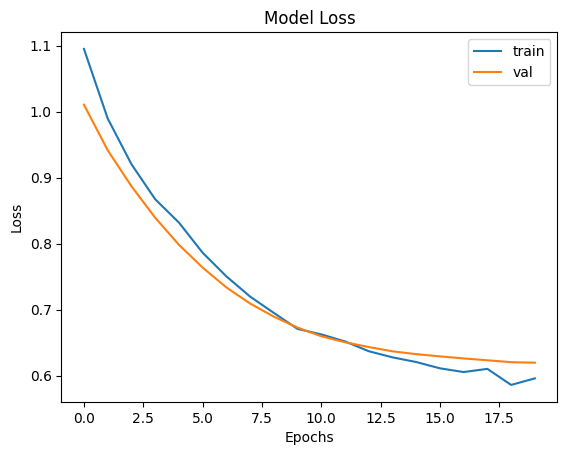

In [25]:
# [14번 문항] 아래 코드의 빈칸을 채우고 실행하세요.

plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend(['train', 'val'])
plt.show()

답안14_1 = 'title'
답안14_2 = 'legend'

<details><summary>힌트 1단계 (접근 방향) - 14번 문항</summary>

빈칸을 채워 코드를 완성한 뒤 실행하세요. 범례를 표시하는 matplotlib 함수입니다. **개념** plt.title 은 제목, plt.xlabel·ylabel 은 가로·세로축 이름, plt.legend 는 선 이름표입니다.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 14번 문항</summary>

빈칸에 들어갈 것은 matplotlib.pyplot(그래프 꾸미기 함수) 쪽 이름입니다. 공식 문서 목록에서 찾아보세요: [matplotlib](https://matplotlib.org/stable/api/pyplot_summary.html)

</details>

<details><summary>힌트 3단계 (코드 구조) - 14번 문항</summary>

코드 구조입니다. `____` 자리에 들어갈 이름은 아래 공식 문서에서 확인하세요(오픈북 사이트).
```python
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.____('Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.____(['train', 'val'])
plt.show()

답안14_1 = '____'   # 빈칸 1에 넣은 이름
답안14_2 = '____'   # 빈칸 2에 넣은 이름
```
- 참고 문서: <https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.title.html>
- 참고 문서: <https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.legend.html>

</details>

### **모든 문항이 완료되었습니다. 수고하셨습니다.**
### 답안을 저장한 뒤 제출해 주시기 바랍니다.

In [26]:
# 전체 자동 채점 — 모든 문항을 푼 뒤 이 셀을 실행하세요. 정답 키는 압축·인코딩되어 있어 내용이 보이지 않습니다.
# (결과 변수 저장형은 지금 노트북에 남아 있는 변수로 채점합니다 — 앞 문항의 변수를 뒤에서 덮어쓰지 마세요)
import base64 as _b64, json as _json, zlib as _zlib
_정답키 = _json.loads(_zlib.decompress(_b64.b64decode("eNqtVs2OmzAQfhXkS4KUIgwJSSrtqXvuaQ8rRRHygpNYMTa1TXfRaqUeeqjUc499h176Uu0+RG3IJiYLBLU9hfH8fB8z35isHgHj4K0DJw7YE5bqR5DwFANtf0RCm6ygVBs5J0xJbc88X5vJDid7Y64egTJJSKqYZDkXyqRmPC0oNucZUjnlipI7Ly/Nk3EjSpBJBjmt7A+GwdPEOdTCD0RqLO1gKMMvcU/rKqKiG1h0Dc0jW5BuwAC2rxF03omA3KEcn3krCFoYcxX4gW4YDNc257yiUf1qW/CCpeMN5UiNWe4xxGSRmSckkRCoHKcbT2KKExWnqsyxHI9Ykd1hMXIdsnF2OkwpoaMmzqgRp/2YSuwYT3VyVYG4rjtxAtemGU4Xi8CH3lyfKU7NiTfzF4HdyNBqpKZ4j+1e/v768/nbl7CloShJcG7eewV+/fj0/P0zWB9B/FP16f9QVYIoNYmbgiXmbKdH9yKk/T0SW5PwCB6MTxGqrvHWuHZFrRzEML0p63HeEWaCA4OVFVSRvBapVCjZm/lXSpzaDZr1KC1WOMsb3YmGy61O7tXcsf5ReHA50xODgSW8hFMZU8O/Pdf4q0EJvH3Pwb9Jtqo6TLdVaLd4D+5+BcNwGc2iuaVg6E1hFNkDivoGxNBfj0ennlrF+KFUV0Db9OqM0+yiZVDPzmI/v7x/8xg2XiI830CBcz1/3L6CgwCCfgC9hWaBWusvOtt/G+tXJ+nfDeA2VgIRBvo+Ci8AfTHlgDrlqzoUszYg+24Nlz3hNWZDyLOwe/F0c+w1O/DxdFfxg+uZJXSbF3u4WEQLW0bLy1NetgziNOM3gQdn1oA9H8JTeehfrg/9BgD0zxCiqee3KgjCAcVhf3FAdOdSgljXGsBgAEhwAeQaJ0QSzm4Ernbdtt9RJCXZkLpuqjpohJ3rov8yYdpGYMC21Ll9GjcfTS5K0C3CqoaX6G+AinMkUCbHZ3fxdN6drVdgvKLOhguHOoQ5dTWKSiyk+S6YC2RMXS+ODaM4dq6unNE1ZhKP1g2YoBvj8A5ezW41wjlPdnK0bqT79lrA6YCpT8/u11f/cBRRtEtWwwCCfgCKt1iXsBHWfwBHhXmw")).decode("utf-8"))


def _같음(a, b, tol=0):
    try:
        if a is None or b is None:
            return a is None and b is None
        if isinstance(b, str) or isinstance(a, str):
            return str(a).strip().strip("'\"").replace(" ", "").lower() == str(b).strip().strip("'\"").replace(" ", "").lower()
        if isinstance(b, (list, tuple)):
            return len(a) == len(b) and all(_같음(x, y, tol) for x, y in zip(a, b))
        return abs(float(a) - float(b)) <= float(tol) + 1e-9
    except Exception:
        return False


def _검사(g, c):
    if c["t"] in ("ast_call", "ast_import", "ast_count", "src_contains"):
        return _코드검사(g, c)
    try:
        t, obj = c["t"], g.get(c.get("name"))
        if t == "exists":
            return c["name"] in g
        if t == "shape":
            return tuple(obj.shape) == tuple(c["value"])
        if t == "len":
            return len(obj) == c["value"]
        if t == "cols_have":
            return all(x in obj.columns for x in c["cols"])
        if t == "cols_lack":
            return all(x not in obj.columns for x in c["cols"])
        if t == "no_na":
            import pandas as _pd
            return int(_pd.DataFrame(obj).isna().sum().sum()) == 0
        if t == "all_numeric":
            import pandas as _pd
            d = _pd.DataFrame(obj)
            return all(_pd.api.types.is_numeric_dtype(d[x]) or _pd.api.types.is_bool_dtype(d[x]) for x in d.columns if x not in c.get("except", []))
        if t == "expr":
            return _같음(eval(c["expr"], g), c["value"], c.get("tol", 0))
        if t == "attr":
            return _같음(getattr(obj, c["attr"]), c["value"], c.get("tol", 0))
        if t == "has_attr":
            return hasattr(obj, c["attr"])
    except Exception:
        return False
    return False


_채점기록 = {}


def 채점(번호=None):
    """번호를 주면 그 문항만, 없으면 전체 문항을 채점해 점수를 보여 줍니다.
    결과 변수 저장형은 그 문항 바로 뒤의 `채점(번호)` 결과를 기억해 둡니다(뒤 문항이 같은 변수를 바꿀 수 있어서)."""
    g = globals()
    대상 = [k for k in _정답키 if 번호 is None or k["no"] == 번호]
    점수 = 0.0
    for k in 대상:
        if k["kind"] in ("var", "code"):
            지금 = (k["kind"] == "code" or k["var"] in g) and all(_검사(g, c) for c in k["checks"])
            if 번호 is not None:
                _채점기록[k["no"]] = 지금
            ok = _채점기록.get(k["no"], 지금) if 번호 is None else 지금
            무엇 = "작성한 코드" if k["kind"] == "code" else f"변수 `{k['var']}`"
        else:
            v = g.get(k["var"])
            ok = v is not None and any(_같음(v, a, k.get("tol", 0)) for a in k["accept"])
            무엇 = f"`{k['var']}`"
        점수 += k["points"] if ok else 0
        print(f"{'✅' if ok else '❌'} {k['no']}번 ({k['points']:g}점) — {무엇} {'정답' if ok else '다시 확인하세요'}")
    if 번호 is None:
        print(f"\n총점: {점수:g} / {sum(k['points'] for k in _정답키):g}")
        globals()["_최종점수"] = 점수
    return 점수


def _셀기록(g, no=None):
    import ast as _ast
    out = []
    for s in (g.get("In") or g.get("_ih") or []):
        if not isinstance(s, str) or "_정답키" in s:
            continue
        if no is not None and f"[{no}번 문항]" not in s:
            continue
        try:
            body = "\n".join(l for l in s.splitlines() if not l.strip().startswith(("#", "%", "!")))
            out.append((_ast.parse(body), body))
        except SyntaxError:
            pass
    return out


def _코드검사(g, c):
    import ast as _ast
    no = c.get("q")
    def _값(n):
        try:
            return _ast.literal_eval(n)
        except Exception:
            try:
                return _ast.unparse(n)
            except Exception:
                return None
    for tree, _ in _셀기록(g, no):
        for nd in _ast.walk(tree):
            if c["t"] == "ast_call" and isinstance(nd, _ast.Call):
                f = nd.func
                name = f.attr if isinstance(f, _ast.Attribute) else (f.id if isinstance(f, _ast.Name) else None)
                if name != c["func"]:
                    continue
                kws = {k.arg: _값(k.value) for k in nd.keywords if k.arg}
                if all(k in kws and _같음(kws[k], v) for k, v in (c.get("kwargs") or {}).items()) and len(nd.args) >= (c.get("n_pos") or 0):
                    return True
            if c["t"] == "ast_import" and isinstance(nd, (_ast.Import, _ast.ImportFrom)):
                if isinstance(nd, _ast.Import) and any(a.name == c["module"] and (c.get("alias") is None or a.asname == c.get("alias")) for a in nd.names):
                    return True
                if isinstance(nd, _ast.ImportFrom) and c.get("name") and nd.module == c["module"] and any(a.name == c["name"] for a in nd.names):
                    return True
    if c["t"] == "ast_count":
        n = sum(1 for tree, _ in _셀기록(g, no) for nd in _ast.walk(tree) if isinstance(nd, _ast.Call)
                and ((nd.func.attr if isinstance(nd.func, _ast.Attribute) else getattr(nd.func, "id", None)) == c["func"]))
        return c.get("min", 0) <= n <= c.get("max", 10 ** 6)
    if c["t"] == "src_contains":
        src = "\n".join(b for _, b in _셀기록(g, no))
        toks = [c["text"]] if isinstance(c["text"], str) else c["text"]
        return all(t in src for t in toks)
    return False


_점수 = 채점()


✅ 1번 (5점) — 작성한 코드 정답
✅ 2번 (5점) — 변수 `df` 정답
✅ 3번 (5점) — `답안3` 정답
✅ 4번 (5점) — 작성한 코드 정답
✅ 5번 (6점) — 변수 `df_temp` 정답
✅ 6번 (6점) — 변수 `df_na` 정답
✅ 7번 (3점) — `답안7_1` 정답
✅ 7번 (3점) — `답안7_2` 정답
✅ 8번 (6점) — 변수 `X_valid` 정답
✅ 9번 (6점) — `답안9` 정답
✅ 10번 (10점) — `답안10` 정답
✅ 11번 (10점) — `답안11` 정답
✅ 12번 (10점) — `답안12` 정답
✅ 13번 (10점) — 변수 `model` 정답
✅ 14번 (5점) — `답안14_1` 정답
✅ 14번 (5점) — `답안14_2` 정답

총점: 100 / 100
